# Importa Bibliotrcas

In [ ]:
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report

# Carrega Notebooks

In [ ]:
df_test = pd.read_csv('data/test.csv')
df_train = pd.read_csv('data/train.csv')

In [ ]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [ ]:
df_train.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


## Analise exploratoria de dados

In [ ]:
df_train.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [ ]:
df_train.corr(numeric_only=True)['is_fraud'].drop('id').sort_values()

hours_since_last_txn           -0.020490
time_of_day_hour               -0.000050
card_age_months                 0.000681
account_balance_usd             0.001077
distance_from_home_km           0.001826
day_of_week                     0.003651
amount_usd                      0.019443
prior_disputes                  0.023644
customer_age                    0.056051
txn_count_last_24h              0.058035
is_ai_generated_scam_attempt    0.060719
used_vpn                        0.071235
billing_shipping_mismatch       0.101115
is_new_merchant                 0.101412
velocity_score                  0.101650
is_foreign_transaction          0.112832
merchant_risk_score             0.125391
ip_country_mismatch             0.148284
cvv_retry_count                 0.212290
is_fraud                        1.000000
Name: is_fraud, dtype: float64

## Tratando dados

In [ ]:
def transform_data(df_1 : pd.DataFrame, df_2 : pd.DataFrame) -> pd.DataFrame:

    TARGET = 'is_fraud'
    ids = df_2['id']

    df_temp = pd.concat([df_1, df_2], axis=0)
    df = df_temp.drop(columns=['id', TARGET])
    targets = df_temp[TARGET].reset_index()

    boolean_features = list(df.select_dtypes(['bool']).columns)
    string_features = list(df.select_dtypes(['string', 'object']).columns)
    numeric_features = list(df.select_dtypes(['number']).columns)

    for b in boolean_features:
        df[b] = df[b].apply(lambda x : 1 if x else 0)

    preprocess = ColumnTransformer(
        transformers= [
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(handle_unknown='ignore', sparse_output=False), string_features)
        ],
        remainder='passthrough'
    )

    df = preprocess.fit_transform(df)
    names = preprocess.get_feature_names_out()
    df = pd.DataFrame(data=df, columns=names).reset_index()

    df = pd.concat([df, targets['is_fraud']], axis=1)
    
    return ids, df

In [ ]:
ids, df = transform_data(df_train, df_test)

In [ ]:
df

,index,num__amount_usd,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__card_age_months,num__customer_age,num__account_balance_usd,num__cvv_retry_count,num__velocity_score,...,cat__device_type_Tablet,cat__device_type_Windows PC,cat__device_type_iPhone,remainder__is_foreign_transaction,remainder__is_new_merchant,remainder__used_vpn,remainder__ip_country_mismatch,remainder__billing_shipping_mismatch,remainder__is_ai_generated_scam_attempt,is_fraud
0,0,-0.091788,0.497909,-1.323864,0.360545,0.204879,0.255436,-0.233957,-0.295240,-1.236175,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,-0.269716,-0.809496,0.010672,-0.045816,-1.586508,-1.309079,0.342041,-0.295240,1.331491,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,-0.360174,-0.863508,0.677940,-0.466813,0.563156,0.199561,-0.299215,-0.295240,1.552366,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,3,-0.207958,-0.239195,0.677940,-0.423766,0.204879,-0.191568,0.044214,-0.295240,0.162697,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,2.810950,-0.927051,0.677940,-0.163764,-1.765646,0.031934,0.359072,-0.295240,1.460335,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999939,999939,-0.261292,-0.342452,-1.991132,-0.418601,-0.690814,0.534814,-0.460714,3.160255,-1.539877,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
999940,999940,-0.351065,-0.628398,1.345209,-1.065163,-1.228230,-0.694448,0.190730,-0.295240,-0.067380,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,NaN
999941,999941,-0.172108,-0.361516,0.677940,1.885259,-0.511676,-1.364954,-0.079008,3.160255,1.064601,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
999942,999942,-0.373643,-0.777725,0.010672,0.281339,-1.228230,-1.309079,0.417325,-0.295240,-0.720801,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN


In [ ]:
# TODO quero remover os que tem similaridade <= 1%

In [ ]:
df.corr(numeric_only=True)['is_fraud'].sort_values()

cat__auth_method_Biometric                -0.035897
cat__auth_method_PIN                      -0.033238
cat__merchant_category_Online Retail      -0.023383
cat__merchant_category_Groceries          -0.022035
num__hours_since_last_txn                 -0.020490
cat__merchant_category_Restaurants        -0.016907
cat__auth_method_OTP                      -0.011875
cat__merchant_category_Fuel               -0.010323
cat__auth_method_3D Secure                -0.009962
cat__merchant_category_Healthcare         -0.006942
cat__merchant_category_Utilities          -0.005671
cat__card_type_Mastercard                 -0.003985
cat__channel_Contactless                  -0.003825
cat__device_type_Android Phone            -0.003329
cat__card_type_Discover                   -0.002649
cat__device_type_Windows PC               -0.001588
cat__channel_ATM                          -0.001353
cat__channel_In-App                       -0.001066
index                                     -0.000644
cat__channel

In [ ]:
df_train = df[:len(df_train)]
df_test = df[len(df_train):]
print(len(df_train), len(df_test))

699960 299984


## train test split

In [ ]:
x = df_train.drop(columns='is_fraud')
y = df_train['is_fraud']

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, shuffle=True, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, shuffle=True, random_state=42, stratify=y_temp)

print(x_train.shape, x_val.shape, x_test.shape)

(489972, 55) (104994, 55) (104994, 55)


In [ ]:
df_train['is_fraud']

0         0.0
1         0.0
2         0.0
3         0.0
4         0.0
         ... 
699955    0.0
699956    0.0
699957    0.0
699958    0.0
699959    0.0
Name: is_fraud, Length: 699960, dtype: float64

In [ ]:
df.columns

Index(['index', 'num__amount_usd', 'num__hours_since_last_txn',
       'num__txn_count_last_24h', 'num__distance_from_home_km',
       'num__card_age_months', 'num__customer_age', 'num__account_balance_usd',
       'num__cvv_retry_count', 'num__velocity_score', 'num__time_of_day_hour',
       'num__day_of_week', 'num__merchant_risk_score', 'num__prior_disputes',
       'cat__merchant_category_Crypto Exchange',
       'cat__merchant_category_Electronics', 'cat__merchant_category_Fuel',
       'cat__merchant_category_Gaming', 'cat__merchant_category_Gift Cards',
       'cat__merchant_category_Groceries', 'cat__merchant_category_Healthcare',
       'cat__merchant_category_Online Retail',
       'cat__merchant_category_Restaurants',
       'cat__merchant_category_Streaming', 'cat__merchant_category_Travel',
       'cat__merchant_category_Utilities', 'cat__card_type_Amex',
       'cat__card_type_Discover', 'cat__card_type_Mastercard',
       'cat__card_type_RuPay', 'cat__card_type_Visa',
  

In [ ]:
skf = StratifiedKFold(n_splits=5)

results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(x_train, y_train), start=1):
    x_tr, x_va = x_train.iloc[train_idx], x_train.iloc[val_idx]
    y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_idx]
    
    xgb_cv = XGBClassifier()
    xgb_cv.fit(x_tr, y_tr,
               verbose = False)
    
    y_pred = xgb_cv.predict_proba(x_va)[:, 1]
    acc = roc_auc_score(y_va, y_pred)
    results.append(acc)
    print(f"Fold {fold}: roc_auc = {acc:.4f}")

Fold 1: roc_auc = 0.9280
Fold 2: roc_auc = 0.9301
Fold 3: roc_auc = 0.9367
Fold 4: roc_auc = 0.9347
Fold 5: roc_auc = 0.9288


In [ ]:
params = {
    'n_estimators': 1000,
    'max_depth': 9,
    'eval_metric': 'auc',
    'learning_rate': 0.09918802139540925,
    'subsample': 0.6684329833808584,
    'colsample_bytree': 0.9151036654152414,
    'gamma': 0.14911870890152207,
    'reg_alpha': 0.10085071428350272,
    'reg_lambda': 0.6724424529145199,
    'min_child_weight': 2,
    'n_jobs': -1,
    'early_stopping_rounds': 10
}

xgb_clf = XGBClassifier(**params)
xgb_clf.fit(x_train, y_train, eval_set = [(x_val, y_val)])

[0]	validation_0-auc:0.90442
[1]	validation_0-auc:0.91482
[2]	validation_0-auc:0.91953
[3]	validation_0-auc:0.92259
[4]	validation_0-auc:0.92459
[5]	validation_0-auc:0.92925
[6]	validation_0-auc:0.93113
[7]	validation_0-auc:0.93131
[8]	validation_0-auc:0.93173
[9]	validation_0-auc:0.93206
[10]	validation_0-auc:0.93194
[11]	validation_0-auc:0.93214
[12]	validation_0-auc:0.93237
[13]	validation_0-auc:0.93296
[14]	validation_0-auc:0.93364
[15]	validation_0-auc:0.93464
[16]	validation_0-auc:0.93507
[17]	validation_0-auc:0.93526
[18]	validation_0-auc:0.93567
[19]	validation_0-auc:0.93615
[20]	validation_0-auc:0.93623
[21]	validation_0-auc:0.93635
[22]	validation_0-auc:0.93650
[23]	validation_0-auc:0.93683
[24]	validation_0-auc:0.93711
[25]	validation_0-auc:0.93760
[26]	validation_0-auc:0.93789
[27]	validation_0-auc:0.93822
[28]	validation_0-auc:0.93838
[29]	validation_0-auc:0.93861
[30]	validation_0-auc:0.93884
[31]	validation_0-auc:0.93896
[32]	validation_0-auc:0.93899
[33]	validation_0-au

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.9151036654152414
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",10
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
y_pred = xgb_clf.predict(x_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(104994,))

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.99      1.00      0.99    103241
         1.0       0.72      0.29      0.41      1753

    accuracy                           0.99    104994
   macro avg       0.86      0.64      0.70    104994
weighted avg       0.98      0.99      0.98    104994



<Axes: >

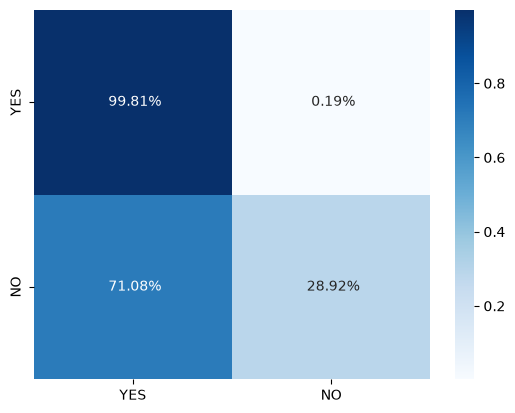

In [ ]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(
    cm,
    cmap='Blues',
    fmt =" .2%",
    annot=True,
    xticklabels=["YES", "NO"],
    yticklabels=["YES", "NO"]
)

In [ ]:
df_test = df_test.drop(columns=['is_fraud'])
out = xgb_clf.predict_proba(df_test)[:,1]
out

array([0.00021178, 0.00039333, 0.13293514, ..., 0.02883385, 0.00053455,
       0.00140521], shape=(299984,), dtype=float32)

In [ ]:
df_final = pd.DataFrame(
    {
        "id": ids,
        "is_fraud": out
    }
)

In [ ]:
df_final.to_csv("solved_01.csv", index=False)

In [ ]:
# kaggle competitions submit -c playground-series-s6e11 -f submission.csv  -m "Message"